In [1]:
# NIM: 202431165
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# NIM: 202431165
# Membaca dataset (menggunakan separator titik koma)
df = pd.read_csv("04_bank_customers.csv", sep=';')

# Melihat 5 baris pertama dan informasi data
display(df.head())
print("\nInformasi Dataset:")
df.info()

print("\nCek Missing Values:")
print(df.isnull().sum())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Cek Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
ho

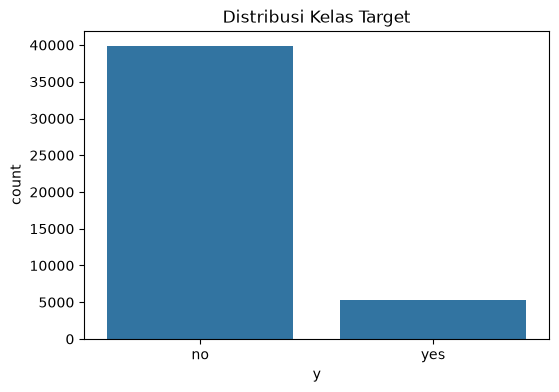

In [3]:
# NIM: 202431165
# Visualisasi distribusi kelas target 'y' (Deposit)
plt.figure(figsize=(6,4))
sns.countplot(x='y', data=df)
plt.title('Distribusi Kelas Target')
plt.show()

In [4]:
# NIM: 202431165
df_encoded = df.copy()

# 1. Label Encoding untuk kolom biner (yes/no)
le = LabelEncoder()
binary_cols = ['default', 'housing', 'loan', 'y']
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# 2. One-Hot Encoding untuk kolom kategorikal yang lebih dari 2 nilai
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
df_encoded = pd.get_dummies(df_encoded, columns=cat_cols, drop_first=True)

# 3. Memisahkan fitur (X) dan target (y)
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

# 4. Splitting Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Standard Scaling (Dibutuhkan untuk optimasi Naive Bayes)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# NIM: 202431165
# Inisialisasi dan melatih model Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Prediksi dan Evaluasi
dt_pred = dt_model.predict(X_test)
dt_acc = accuracy_score(y_test, dt_pred)

print(f"Akurasi Decision Tree: {dt_acc * 100:.2f}%")
print("\nLaporan Klasifikasi Decision Tree:\n", classification_report(y_test, dt_pred))

Akurasi Decision Tree: 87.39%

Laporan Klasifikasi Decision Tree:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93      7952
           1       0.48      0.50      0.49      1091

    accuracy                           0.87      9043
   macro avg       0.70      0.71      0.71      9043
weighted avg       0.88      0.87      0.88      9043



In [6]:
# NIM: 202431165
# Inisialisasi dan melatih model Naive Bayes (Gaussian)
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Prediksi dan Evaluasi
nb_pred = nb_model.predict(X_test_scaled)
nb_acc = accuracy_score(y_test, nb_pred)

print(f"Akurasi Naive Bayes: {nb_acc * 100:.2f}%")
print("\nLaporan Klasifikasi Naive Bayes:\n", classification_report(y_test, nb_pred))

Akurasi Naive Bayes: 85.69%

Laporan Klasifikasi Naive Bayes:
               precision    recall  f1-score   support

           0       0.93      0.91      0.92      7952
           1       0.42      0.47      0.44      1091

    accuracy                           0.86      9043
   macro avg       0.67      0.69      0.68      9043
weighted avg       0.87      0.86      0.86      9043



In [ ]:

S